In [1]:
# ¿Cómo podemos predecir el consumo de combustible (MPG) de un automóvil a partir de sus características técnicas?

import pandas as pd

dataset = pd.read_csv("../data/auto_mpg.csv")
dataset.head()



# --

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,18.0,8,307.0,130.0,3504.0,12.0,70,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,1


In [2]:
# --

# Tamaño del dataset
dataset.shape

(398, 8)

In [3]:
# Búsqueda de valores nulos

dataset.isna().sum()

MPG             0
Cylinders       0
Displacement    0
Horsepower      6
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64

In [4]:
# ---

# Origin identifica el país de fabricación; sus valores son etiquetas, no una escala numérica.

dataset["Origin"].value_counts()

Origin
1    249
3     79
2     70
Name: count, dtype: int64

In [5]:
# --
 
# La categoría se conserva hasta que OneHotEncoder la transforma sin imponer un orden entre países.

dataset["Origin"] = dataset["Origin"].astype("category")
dataset.dtypes["Origin"]

CategoricalDtype(categories=[1, 2, 3], ordered=False, categories_dtype=int64)

In [6]:
# Se debe conservar la categoría de origen para codificarla después de separar entrenamiento y prueba.

dataset.head()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,18.0,8,307.0,130.0,3504.0,12.0,70,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,1


In [8]:
# Se deben separar vehículos para entrenamiento y prueba con una partición reproducible.

from sklearn.model_selection import train_test_split

train_dataset, test_dataset = train_test_split(
    dataset,
    train_size=0.8,
    random_state=0,
)

ModuleNotFoundError: No module named 'sklearn'

In [9]:
# ---

# Horsepower debe aparecer porque se usa directamente en la primera especificación predictiva.

import seaborn as sns

sns.pairplot(
    train_dataset[["MPG", "Cylinders", "Displacement", "Horsepower", "Weight"]],
    diag_kind="kde",
)

NameError: name 'train_dataset' is not defined

In [ ]:
# Cálculo de algunas estadísticas generales

train_dataset.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
MPG,318.0,23.574843,7.776499,9.0,17.50,23.0,29.00,46.6
Cylinders,318.0,5.452830,1.706170,3.0,4.00,4.0,8.00,8.0
Displacement,318.0,191.800314,102.795417,68.0,101.75,148.5,262.00,455.0
Horsepower,313.0,103.702875,37.723750,46.0,75.00,93.0,125.00,230.0
Weight,318.0,2963.393082,845.227078,1649.0,2216.25,2822.5,3561.25,5140.0
Acceleration,318.0,15.644654,2.701224,8.0,14.00,15.5,17.15,24.8
Model Year,318.0,76.147799,3.652083,70.0,73.00,76.0,79.00,82.0


In [ ]:

# Particionamiento de los datos en features y labels

train_features = train_dataset.copy()
train_labels = train_features.pop("MPG")

test_features = test_dataset.copy()
test_labels = test_features.pop("MPG")


In [ ]:
# Se debe observar cómo StandardScaler centra y escala las variables numéricas.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numeric_columns = train_dataset.select_dtypes(include="number").columns.drop("MPG")

pd.DataFrame(
    data=scaler.fit_transform(train_dataset[numeric_columns]),
    columns=numeric_columns,
).describe().transpose()[["mean", "std"]]

,mean,std
Cylinders,5.167076e-17,1.001576
Displacement,-5.586028e-18,1.001576
Horsepower,7.661603e-17,1.001601
Weight,8.658343e-17,1.001576
Acceleration,-8.099740e-17,1.001576
Model Year,4.650368e-16,1.001576


In [ ]:
# Regresión lineal con una sola variable (Horsepower)

horsepower_scaler = StandardScaler()

train_horsepower = train_features[["Horsepower"]]
test_horsepower = test_features[["Horsepower"]]

horsepower_scaler.fit(train_horsepower)

standarized_train_horsepower = horsepower_scaler.transform(train_horsepower)
standarized_test_horsepower = horsepower_scaler.transform(test_horsepower)

In [ ]:
# Modelo de regresión lineal

from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer

horsepower_model = LinearRegression()
horsepower_imputer = SimpleImputer(strategy="median")
standarized_train_horsepower = horsepower_imputer.fit_transform(standarized_train_horsepower)
standarized_test_horsepower = horsepower_imputer.transform(standarized_test_horsepower)

horsepower_model.fit(standarized_train_horsepower, train_labels)

LinearRegression()

In [ ]:
# ---

# Intercepto
horsepower_model.intercept_

23.547324163897578

In [ ]:
# Coeficientes
horsepower_model.coef_

array([-6.15889812])

In [ ]:
# Coeficientes
horsepower_model.coef_

# --

# Predicción. Preparación de las variables independientes

import numpy as np

x = pd.DataFrame({"Horsepower": np.linspace(0, 250, 251)})
x.head()

# --

,Horsepower
0,0.0
1,1.0
2,2.0
3,3.0
4,4.0


In [ ]:
# Predicción

scaled_x = horsepower_scaler.transform(x)
y = horsepower_model.predict(scaled_x)
y[:5]



array([40.50529303, 40.34176846, 40.17824388, 40.0147193 , 39.85119472])

In [ ]:
import matplotlib.pyplot as plt


def plot_horsepower(x, y):
    plt.scatter(train_features["Horsepower"], train_labels, label="Data")
    plt.plot(x, y, color="k", label="Predictions")
    plt.xlabel("Horsepower")
    plt.ylabel("MPG")
    plt.legend()

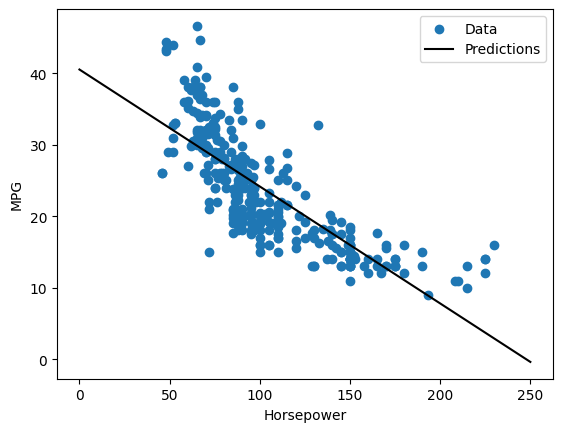

In [ ]:
# --
import matplotlib.pyplot as plt


def plot_horsepower(x, y):
    plt.scatter(train_features["Horsepower"], train_labels, label="Data")
    plt.plot(x, y, color="k", label="Predictions")
    plt.xlabel("Horsepower")
    plt.ylabel("MPG")
    plt.legend()

# --

plot_horsepower(x, y)


#import matplotlib.pyplot as plt


def plot_horsepower(x, y):
    plt.scatter(train_features["Horsepower"], train_labels, label="Data")
    plt.plot(x, y, color="k", label="Predictions")
    plt.xlabel("Horsepower")
    plt.ylabel("MPG")
    plt.legend()

# --

In [ ]:
# Evaluación

from sklearn.metrics import mean_squared_error

test_results = {}

y_pred = horsepower_model.predict(standarized_test_horsepower)

test_results["horsepower_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=y_pred,
)

test_results


{'horsepower_model': 30.965374890506695}

In [ ]:

# --
# Se deben ajustar el escalamiento y la codificación solo con los vehículos de entrenamiento.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_features = train_features.select_dtypes(include="number").columns.tolist()
categorical_features = ["Origin"]

features_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "origin",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ],
)

standarized_train_features = features_preprocessor.fit_transform(train_features)
standarized_test_features = features_preprocessor.transform(test_features)

linear_model = LinearRegression()
standarized_train_features = SimpleImputer(strategy="median").fit_transform(
    standarized_train_features
)
linear_model.fit(standarized_train_features, train_labels)

LinearRegression()

In [ ]:
# ---

# Intercepto
linear_model.intercept_

# ---

24.37695965903193

In [ ]:

# Coeficientes
linear_model.coef_

array([-0.68202582,  2.58711517, -0.78847151, -5.62721043,  0.5142342 ,
        2.7905719 , -1.93166567,  0.72527708,  1.20638859])

{'horsepower_model': 30.965374890506695, 'linear_model': 10.953502656917813}

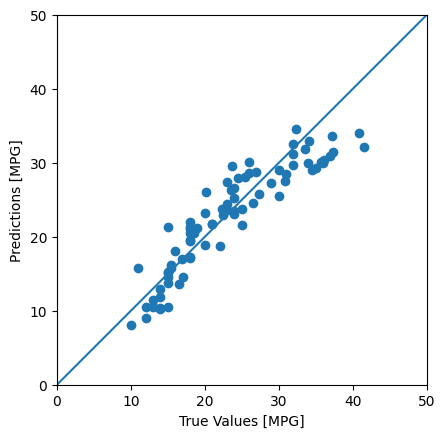

In [ ]:

def plot_predictions(y_true, y_pred):

    plt.axes(aspect="equal") 
    plt.scatter(y_true, y_pred)
    plt.xlabel("True Values [MPG]")
    plt.ylabel("Predictions [MPG]")
    lims = [0, 50]
    plt.xlim(lims)
    plt.ylim(lims)
    _ = plt.plot(lims, lims)

test_predictions = linear_model.predict(standarized_test_features)

plot_predictions(
    y_true=test_labels,
    y_pred=test_predictions,
)

# --

test_results["linear_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=test_predictions,
)

test_results

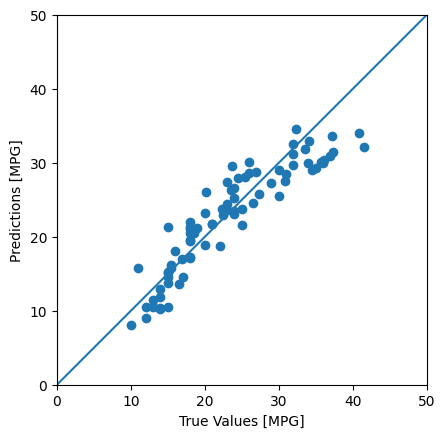

In [ ]:
# --

features_imputer = SimpleImputer(strategy="median")

standarized_train_features = features_imputer.fit_transform(
    standarized_train_features
)
standarized_test_features = features_imputer.transform(
    standarized_test_features
)

linear_model.fit(standarized_train_features, train_labels)

test_predictions = linear_model.predict(standarized_test_features)

plot_predictions(
    y_true=test_labels,
    y_pred=test_predictions,
)


In [ ]:
test_results["linear_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=test_predictions,
)

test_results

# ---

{'horsepower_model': 30.965374890506695, 'linear_model': 10.953502656917813}

In [ ]:
# Se agregan un término cuadrático y una interacción Weight × Horsepower para flexibilizar el modelo lineal.

train_features_flexible = train_features.copy()
test_features_flexible = test_features.copy()

for features in [train_features_flexible, test_features_flexible]:
    features["Horsepower_squared"] = features["Horsepower"] ** 2
    features["Weight_x_Horsepower"] = features["Weight"] * features["Horsepower"]

train_features_flexible[["Horsepower", "Horsepower_squared", "Weight", "Weight_x_Horsepower"]].head()

,Horsepower,Horsepower_squared,Weight,Weight_x_Horsepower
64,150.0,22500.0,4135.0,620250.0
55,60.0,3600.0,1834.0,110040.0
317,78.0,6084.0,2188.0,170664.0
102,46.0,2116.0,1950.0,89700.0
358,74.0,5476.0,2635.0,194990.0


In [ ]:
# ---

# Se compara la regresión base con una especificación lineal que incluye los nuevos términos.

flexible_numeric_features = train_features_flexible.select_dtypes(include="number").columns.tolist()

flexible_features_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), flexible_numeric_features),
        ("origin", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
)

flexible_train_features = flexible_features_preprocessor.fit_transform(train_features_flexible)
flexible_test_features = flexible_features_preprocessor.transform(test_features_flexible)

linear_flexible_model = LinearRegression()
flexible_imputer = SimpleImputer(strategy="median")
flexible_train_features = flexible_imputer.fit_transform(flexible_train_features)
flexible_test_features = flexible_imputer.transform(flexible_test_features)

linear_flexible_model.fit(flexible_train_features, train_labels)

flexible_predictions = linear_flexible_model.predict(flexible_test_features)
test_results["linear_flexible_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=flexible_predictions,
)

test_results

{'horsepower_model': 30.965374890506695,
 'linear_model': 10.953502656917813,
 'linear_flexible_model': 8.50896767483206}

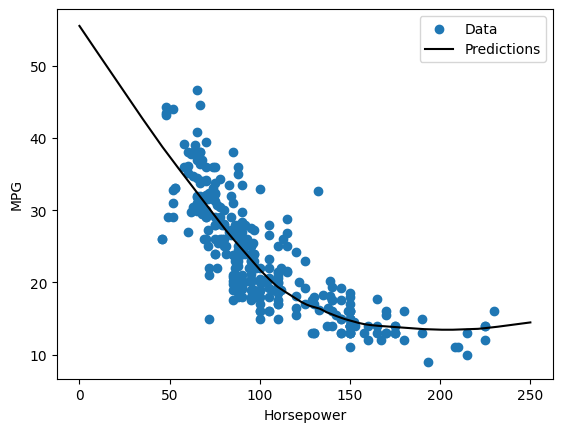

In [ ]:
# Red neuronal con una sola entrada (Horsepower)

from sklearn.neural_network import MLPRegressor

mlp_horsepower = MLPRegressor(
    max_iter=10000,
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    validation_fraction=0.2,
    early_stopping=True,
    random_state=0,
)
mlp_horsepower.fit(standarized_train_horsepower, train_labels)

y = mlp_horsepower.predict(scaled_x)
plot_horsepower(x, y)

In [ ]:
# --

y_pred = mlp_horsepower.predict(standarized_test_horsepower)

test_results["mlp_horsepower"] = mean_squared_error(
    y_true=test_labels,
    y_pred=y_pred,
)

test_results

{'horsepower_model': 30.965374890506695,
 'linear_model': 10.953502656917813,
 'linear_flexible_model': 8.50896767483206,
 'mlp_horsepower': 27.495614054956878}

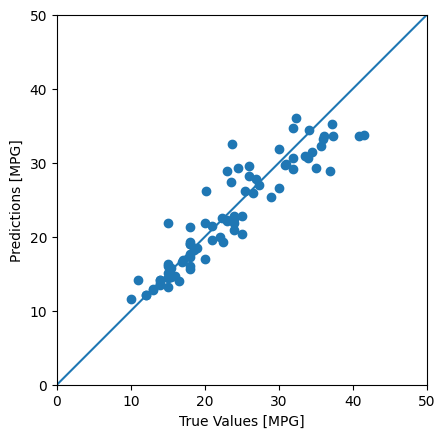

In [ ]:
# Red neuronal con todas las variables

mlp = MLPRegressor(
    max_iter=10000,
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    validation_fraction=0.2,
    early_stopping=True,
    random_state=0,
)

mlp.fit(standarized_train_features, train_labels)

test_predictions = mlp.predict(standarized_test_features)

plot_predictions(
    y_true=test_labels,
    y_pred=test_predictions,
)

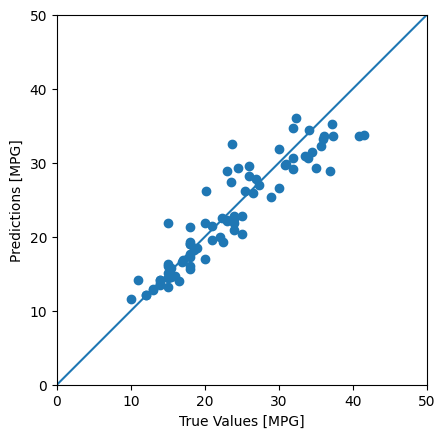

In [ ]:

# Red neuronal con todas las variables

mlp = MLPRegressor(
    max_iter=10000,
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    validation_fraction=0.2,
    early_stopping=True,
    random_state=0,
)

mlp.fit(standarized_train_features, train_labels)

test_predictions = mlp.predict(standarized_test_features)

plot_predictions(
    y_true=test_labels,
    y_pred=test_predictions,
)


test_results["mlp"] = mean_squared_error(
    y_true=test_labels,
    y_pred=test_predictions,
)


In [ ]:
# Desempeño de los modelos

pd.DataFrame(test_results, index=["Mean squared error [MPG]"]).T.sort_values(
    by="Mean squared error [MPG]", ascending=False
)


,Mean squared error [MPG]
horsepower_model,30.965375
mlp_horsepower,27.495614
linear_model,10.953503
mlp,9.033598
linear_flexible_model,8.508968


In [ ]:
# Se almacenan los modelos, preprocesadores y la comparación de desempeño ajustados con entrenamiento.

import os
import pickle


with open("../submission/mlp.pkl", "wb") as file:
    pickle.dump(mlp, file)

with open("../submission/features_preprocessor.pkl", "wb") as file:
    pickle.dump(features_preprocessor, file)

with open("../submission/linear_flexible_model.pkl", "wb") as file:
    pickle.dump(linear_flexible_model, file)

with open("../submission/flexible_features_preprocessor.pkl", "wb") as file:
    pickle.dump(flexible_features_preprocessor, file)

pd.DataFrame(
    {
        "model": list(test_results),
        "test_mse": list(test_results.values()),
    }
).to_csv("../submission/model_comparison.csv", index=False)

In [ ]:

# --

# La predicción reutiliza el mismo tratamiento categórico aplicado durante el ajuste.

import pandas as pd

dataset = pd.read_csv("../data/auto_mpg.csv")
dataset = dataset.dropna()
dataset["Origin"] = dataset["Origin"].astype("category")
y_true = dataset.pop("MPG")

with open("../submission/mlp.pkl", "rb") as file:
    new_mlp = pickle.load(file)

with open("../submission/features_preprocessor.pkl", "rb") as file:
    new_features_preprocessor = pickle.load(file)

standarized_dataset = new_features_preprocessor.transform(dataset)
y_pred = new_mlp.predict(standarized_dataset)

mean_squared_error(
    y_true=y_true,
    y_pred=y_pred,
)

7.086278329605052